# 01 — Process Mining анализ «закупка → контрактация»

**Проект:** `pm_mvp_contracting` (MVP Process Mining для горнодобывающего холдинга, контекст ЕвроХим / Центр компетенций).
**Данные:** синтетический event log, `SEED = 42` — 50 000 кейсов, 1 094 474 события, 25 активностей, период 2024-01…2025-04.
**Стек:** pm4py 2.7 (discovery + performance), pandas, matplotlib, Graphviz (рендер графов).

Что считает ноутбук:

| Блок | Метрика | AC |
|---|---|---|
| DFG | узлы/рёбра, частоты переходов | AC-2 |
| Petri net (Inductive Miner) | модель процесса + fitness (token-based replay) | AC-9 |
| Variant analysis | топ-10 вариантов, частота, доля, средняя длительность | AC-5 |
| Bottlenecks | средняя длительность/σ/P90 на активность, топ-3 по вкладу | AC-6 |
| Стоимость простоя | `Σ duration_days × downtime_cost_per_day` | AC-4 |

Артефакты: `docs/img/dfg.png`, `docs/img/petri_net.png`, `docs/img/variants.png`, `docs/img/bottlenecks.png`.

**Запуск:** `jupyter nbconvert --to notebook --execute --inplace notebooks/01_pm4py_analysis.ipynb`
(нужен Graphviz: `dot` в PATH — иначе `pm4py.save_vis_*` упадёт с `ExecutableNotFound`).

## 1. Импорты и загрузка event log

In [1]:
# ============================================================
# Ячейка 1: импорты, пути проекта, загрузка event log
# ============================================================
import logging
import sys
import time
import warnings
from pathlib import Path

import contextlib
import io

import matplotlib
matplotlib.use("Agg")  # headless-режим: сохраняем PNG, не открываем окна
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")  # шум deprecation-варнингов pm4py/pandas 3
logging.basicConfig(stream=sys.stdout, level=logging.INFO, format="%(message)s", force=True)
log = logging.getLogger("pm4py_mvp")

# pm4py при импорте печатает баннер лицензии в stderr — убираем его из отчёта
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import pm4py


def find_project_root(start: Path) -> Path:
    """Поднимается по дереву каталогов вверх до корня проекта (где лежит events.csv)."""
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "processed" / "events.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Не найден data/processed/events.csv — сначала запустите tools/generate_synthetic.py"
    )


ROOT = find_project_root(Path.cwd().resolve())
EVENTS_CSV = ROOT / "data" / "processed" / "events.csv"
IMG_DIR = ROOT / "docs" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

IMG_DFG = IMG_DIR / "dfg.png"
IMG_PETRI = IMG_DIR / "petri_net.png"
IMG_VARIANTS = IMG_DIR / "variants.png"
IMG_BOTTLENECKS = IMG_DIR / "bottlenecks.png"

# Читаем только нужные колонки: events.csv ~260 МБ / 1.09 млн строк
USECOLS = [
    "case_id", "activity", "timestamp", "resource", "category",
    "amount", "is_import", "is_rejected", "downtime_cost_per_day",
]
DTYPES = {
    "amount": "float64",
    "is_import": "int8",
    "is_rejected": "int8",
    "downtime_cost_per_day": "int64",
}

t0 = time.perf_counter()
df = pd.read_csv(EVENTS_CSV, usecols=USECOLS, dtype=DTYPES)
df["timestamp"] = pd.to_datetime(df["timestamp"])
log.info(
    "Загружено: %s строк × %d колонок за %.1f с, RAM %.0f МБ",
    f"{len(df):,}".replace(",", " "),
    len(df.columns),
    time.perf_counter() - t0,
    df.memory_usage(deep=True).sum() / 2 ** 20,
)

df.head(3)

Загружено: 1 094 474 строк × 9 колонок за 5.9 с, RAM 364 МБ


,case_id,activity,timestamp,resource,category,amount,is_import,is_rejected,downtime_cost_per_day
0,CASE-000001,Requisition Created,2024-02-17 11:00:00,Специалист по закупкам,ЗИП (запчасти),3695532.51,0,0,454785
1,CASE-000001,Technical Review Started,2024-02-17 17:00:00,Главный механик,ЗИП (запчасти),3695532.51,0,0,454785
2,CASE-000001,Technical Review Completed,2024-02-20 09:00:00,Главный механик,ЗИП (запчасти),3695532.51,0,0,454785


## 2. Подготовка: XES-формат и целостность лога

`pm4py.format_dataframe` добавляет стандартные колонки (`case:concept:name`, `concept:name`, `time:timestamp`), после чего лог проверяется теми же правилами, что и `tools/validate.py`. Здесь же строится таблица уровня кейса — она переиспользуется в блоках вариантов, bottlenecks и стоимости.

In [2]:
# ============================================================
# Ячейка 2: приведение к XES-формату + проверка совместимости
# ============================================================
t0 = time.perf_counter()
# format_dataframe добавляет стандартные колонки pm4py/XES:
#   case:concept:name (кейс), concept:name (активность), time:timestamp (время)
# Важно: функция мутирует переданный df — это ожидаемое поведение pm4py 2.7
df = pm4py.format_dataframe(
    df, case_id="case_id", activity_key="activity", timestamp_key="timestamp"
)
log.info("format_dataframe: %.1f с, колонок стало %d", time.perf_counter() - t0, len(df.columns))

# Оставляем только нужное дальше — экономим RAM (ограничение стенда: 8 ГБ)
LOG = df[[
    "case:concept:name", "concept:name", "time:timestamp", "resource",
    "category", "amount", "is_import", "is_rejected", "downtime_cost_per_day",
]].copy()
del df

# Ключи задаём явно, не полагаясь на автоопределение pm4py
KEYS = dict(
    case_id_key="case:concept:name",
    activity_key="concept:name",
    timestamp_key="time:timestamp",
)

n_events = len(LOG)
n_cases = LOG["case:concept:name"].nunique()
n_activities = LOG["concept:name"].nunique()

# Сортировка по кейсу и времени — база для всех проверок и расчётов ниже
srt = LOG.sort_values(["case:concept:name", "time:timestamp"], kind="mergesort")

# Те же проверки, что делает tools/validate.py
xes_checks = {
    "NULL в case_id": int(LOG["case:concept:name"].isna().sum()),
    "NULL в timestamp": int(LOG["time:timestamp"].isna().sum()),
    "нарушений монотонности времени": int(
        (
            srt.groupby("case:concept:name", sort=False)["time:timestamp"]
            .diff()
            .dt.total_seconds()
            < 0
        ).sum()
    ),
    "дублей (case_id, activity, timestamp)": int(
        LOG.duplicated(["case:concept:name", "concept:name", "time:timestamp"]).sum()
    ),
}
for check_name, check_value in xes_checks.items():
    log.info("  %-40s %d", check_name, check_value)

xes_ok = all(check_value == 0 for check_value in xes_checks.values())
log.info(
    "Итог: событий %s, кейсов %s, активностей %d → XES-формат %s",
    f"{n_events:,}".replace(",", " "),
    f"{n_cases:,}".replace(",", " "),
    n_activities,
    "совместим ✓" if xes_ok else "НЕ совместим ✗",
)
if not xes_ok:
    raise ValueError("Event log не проходит проверки XES — см. значения выше")

# Таблица уровня кейса: длительность, вариант, атрибуты (используется в ячейках 5–7)
per_case = srt.groupby("case:concept:name", sort=False).agg(
    start=("time:timestamp", "min"),
    end=("time:timestamp", "max"),
    variant=("concept:name", tuple),  # последовательность активностей кейса
    n_events=("concept:name", "size"),
    category=("category", "first"),
    downtime_cost_per_day=("downtime_cost_per_day", "first"),
    is_import=("is_import", "first"),
    is_rejected=("is_rejected", "first"),
)
per_case["duration_days"] = (per_case["end"] - per_case["start"]).dt.total_seconds() / 86400

log.info(
    "Длительность кейса: средняя %.2f дн, медиана %.2f дн, максимум %.2f дн",
    per_case["duration_days"].mean(),
    per_case["duration_days"].median(),
    per_case["duration_days"].max(),
)
per_case.head(3)

format_dataframe: 2.3 с, колонок стало 14


  NULL в case_id                           0


  NULL в timestamp                         0


  нарушений монотонности времени           0


  дублей (case_id, activity, timestamp)    0


Итог: событий 1 094 474, кейсов 50 000, активностей 25 → XES-формат совместим ✓


Длительность кейса: средняя 35.68 дн, медиана 33.33 дн, максимум 131.67 дн


,start,end,variant,n_events,category,downtime_cost_per_day,is_import,is_rejected,duration_days
case:concept:name,,,,,,,,,
CASE-000001,2024-02-17 11:00:00+00:00,2024-03-22 09:00:00+00:00,"(Requisition Created, Technical Review Started...",25,ЗИП (запчасти),454785,0,0,33.916667
CASE-000002,2024-05-22 10:00:00+00:00,2024-06-11 15:00:00+00:00,"(Requisition Created, Technical Review Started...",11,Химические реагенты,245852,0,1,20.208333
CASE-000003,2024-07-12 09:00:00+00:00,2024-07-28 10:00:00+00:00,"(Requisition Created, Technical Review Started...",18,Химические реагенты,280331,0,0,16.041667


## 3. Directly-Follows Graph

Прямой граф следования: узлы — активности, рёбра — переходы, вес — частота. AC-2 требует ≥ 20 узлов и ≥ 25 рёбер.

DFG: 25 узлов (активностей), 28 рёбер (переходов) за 3.4 с


Сохранено: docs\img\dfg.png (165 КБ, 2.3 с)


,from,to,frequency,share_percent
0,Draft Contract Created,Legal Review Started,56935,5.45
1,Legal Review Started,Legal Review Completed,56678,5.43
2,Requisition Created,Technical Review Started,50000,4.79
3,Technical Review Started,Technical Review Completed,50000,4.79
4,HSE Review Started,HSE Review Completed,48623,4.66
5,HSE Review Completed,Signature Requested,48383,4.63
6,Signature Requested,Signed by Buyer,48136,4.61
7,Signed by Buyer,Signed by Supplier,47899,4.59
8,Signed by Supplier,PO Issued,47719,4.57
9,PO Issued,Goods Shipped,47602,4.56


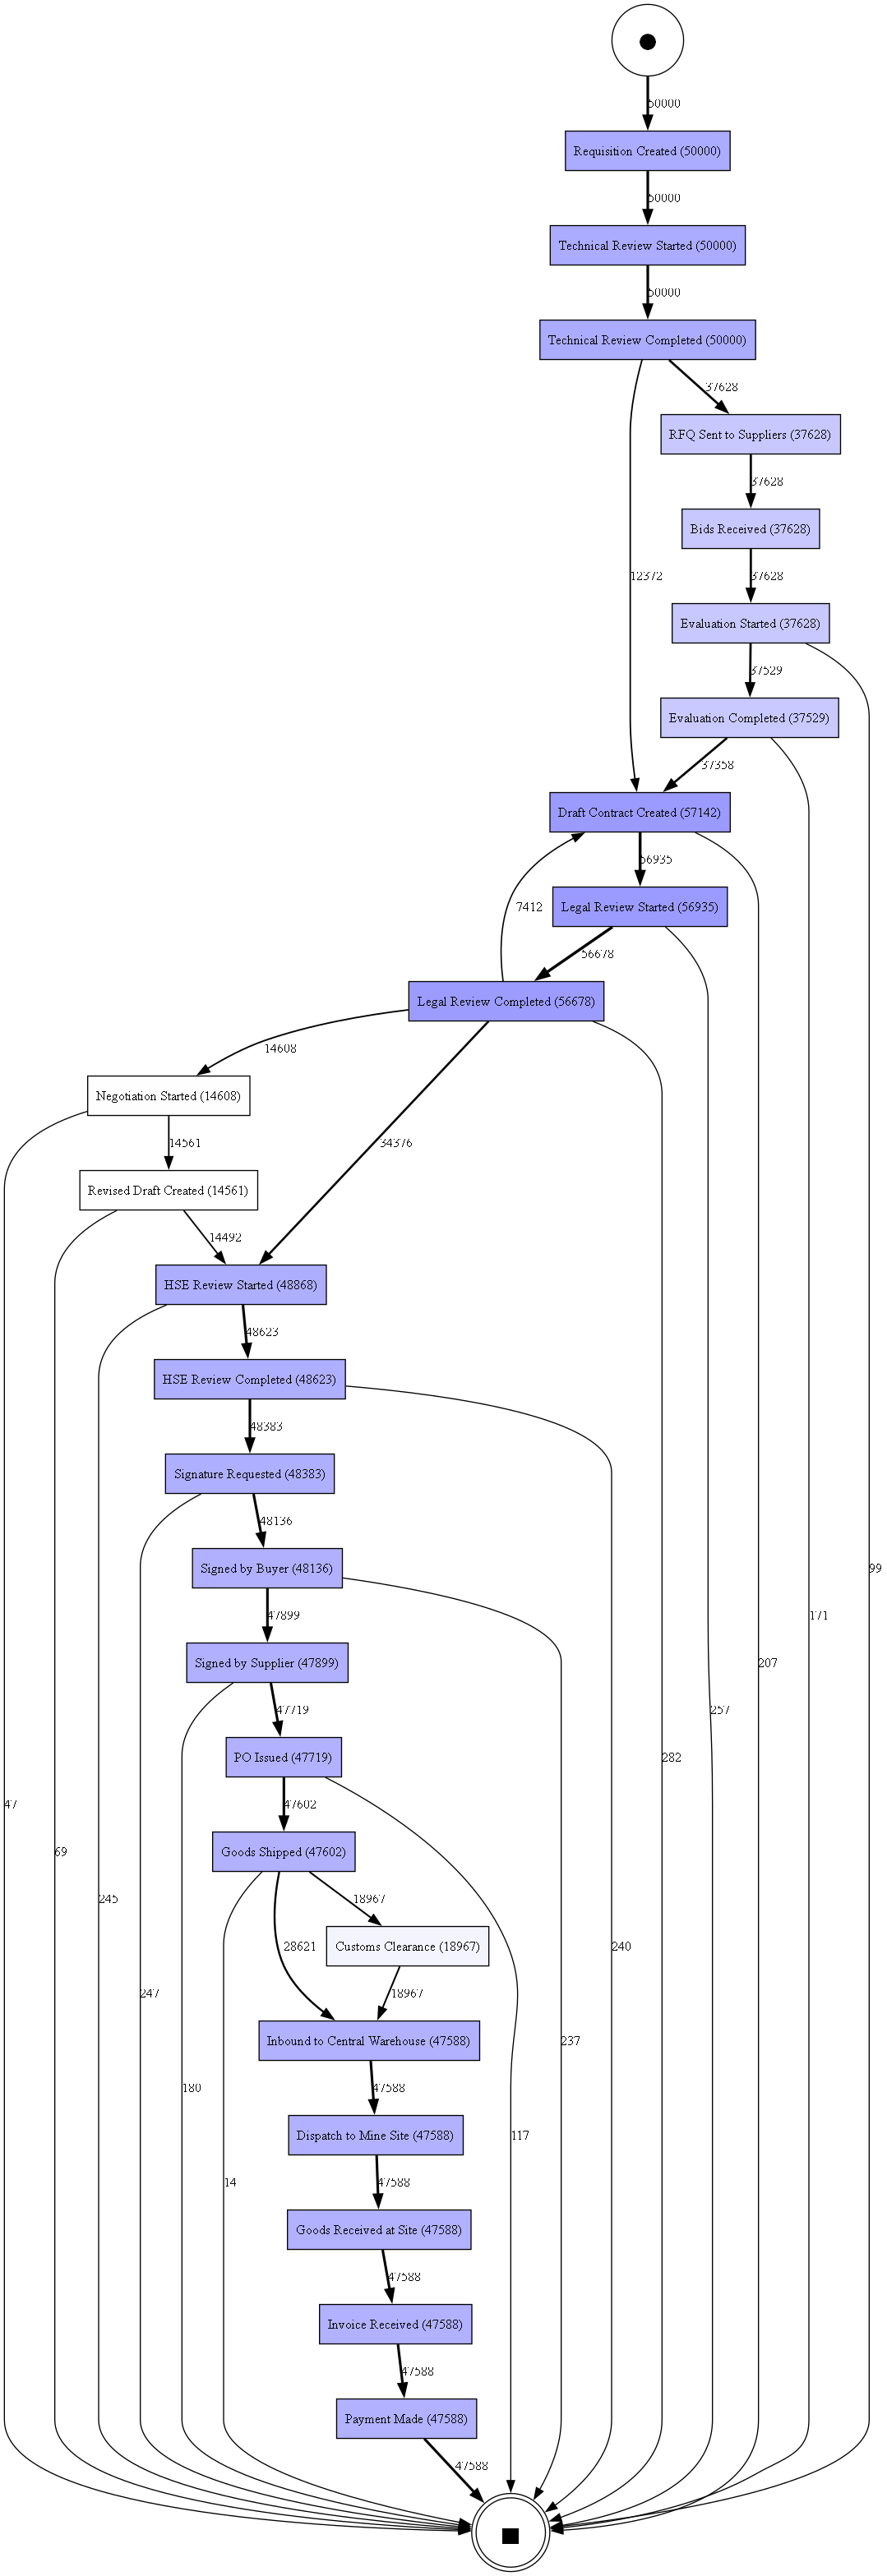

In [3]:
# ============================================================
# Ячейка 3: Directly-Follows Graph (DFG) → docs/img/dfg.png
# ============================================================
t0 = time.perf_counter()
dfg, start_activities, end_activities = pm4py.discover_dfg(LOG, **KEYS)

dfg_nodes = sorted({activity for pair in dfg for activity in pair})
log.info(
    "DFG: %d узлов (активностей), %d рёбер (переходов) за %.1f с",
    len(dfg_nodes), len(dfg), time.perf_counter() - t0,
)

# AC-2: в графе ≥ 20 узлов и ≥ 25 рёбер
assert len(dfg_nodes) >= 20, f"AC-2: узлов {len(dfg_nodes)} < 20"
assert len(dfg) >= 25, f"AC-2: рёбер {len(dfg)} < 25"

# Самые частые переходы: где реально идёт поток кейсов.
# Доля считается от общего числа переходов (сумма > 100% кейсов возможна из-за
# повторных проходов, например возврата Draft Contract → Legal Review).
dfg_edges = pd.DataFrame(
    [{"from": src, "to": dst, "frequency": freq} for (src, dst), freq in dfg.items()]
).sort_values("frequency", ascending=False)
dfg_edges["share_percent"] = 100 * dfg_edges["frequency"] / dfg_edges["frequency"].sum()

t0 = time.perf_counter()
# rankdir="TB" читается лучше, чем LR: 25 активностей в LR дают полосу 7 000 px шириной
pm4py.save_vis_dfg(dfg, start_activities, end_activities, str(IMG_DFG), rankdir="TB")
log.info(
    "Сохранено: %s (%.0f КБ, %.1f с)",
    IMG_DFG.relative_to(ROOT), IMG_DFG.stat().st_size / 1024, time.perf_counter() - t0,
)

display(dfg_edges.head(10).reset_index(drop=True).round(2))
display(Image(filename=str(IMG_DFG), width=700))

## 4. Petri net (Inductive Miner)

Модель процесса, восстановленная по логу. Качество проверяется token-based replay на выборке 2 000 кейсов (на всём логе метрика считается минутами).

Petri net (Inductive Miner): 28 позиций, 44 переходов за 1.4 с


Сохранено: docs\img\petri_net.png (225 КБ)


replaying log with TBR, completed traces ::   0%|          | 0/47 [00:00<?, ?it/s]

Token-based replay на 2 000 кейсах за 0.5 с: average_trace_fitness = 1.000, fitting traces = 100.0%


,value
perc_fit_traces,100.0
average_trace_fitness,1.0
log_fitness,1.0
percentage_of_fitting_traces,100.0


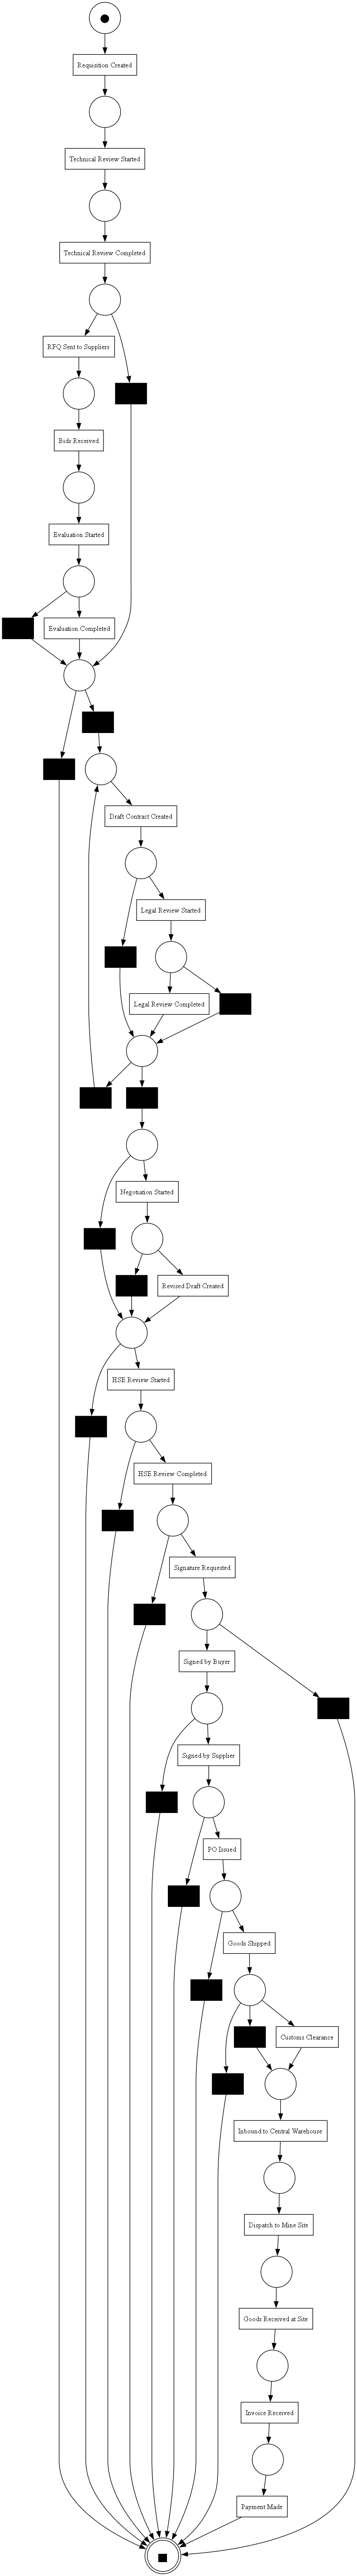

In [4]:
# ============================================================
# Ячейка 4: Petri net (Inductive Miner) → docs/img/petri_net.png
# ============================================================
t0 = time.perf_counter()
net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(LOG, **KEYS)
log.info(
    "Petri net (Inductive Miner): %d позиций, %d переходов за %.1f с",
    len(net.places), len(net.transitions), time.perf_counter() - t0,
)

pm4py.save_vis_petri_net(
    net, initial_marking, final_marking, str(IMG_PETRI), rankdir="TB"
)
log.info("Сохранено: %s (%.0f КБ)", IMG_PETRI.relative_to(ROOT), IMG_PETRI.stat().st_size / 1024)

# Качество модели: token-based replay на детерминированной выборке (первые 2 000 кейсов).
# На всём логе метрика считается минутами и для MVP-демо не нужна.
sample_case_ids = set(per_case.index[:2000])
sample_log = LOG[LOG["case:concept:name"].isin(sample_case_ids)]

t0 = time.perf_counter()
fitness = pm4py.fitness_token_based_replay(
    sample_log, net, initial_marking, final_marking, **KEYS
)
log.info(
    "Token-based replay на %s кейсах за %.1f с: average_trace_fitness = %.3f, "
    "fitting traces = %.1f%%",
    f"{len(sample_log['case:concept:name'].unique()):,}".replace(",", " "),
    time.perf_counter() - t0,
    fitness["average_trace_fitness"],
    fitness["perc_fit_traces"],
)

display(pd.DataFrame([fitness]).T.rename(columns={0: "value"}))
display(Image(filename=str(IMG_PETRI), width=700))

## 5. Variant analysis

Вариант — уникальная последовательность активностей кейса. Смотрим топ-10 по частоте, долю кейсов и среднюю длительность. **Важно:** в этом датасете 80 вариантов, и топ-1 покрывает ~25.6% кейсов, то есть порог AC-5 (≥ 30%) не достигается — это ограничение синтетических данных, а не расчёта (подробности — в отчёте по Task 3).

Вариантов процесса: 80 за 0.9 с (50 000 кейсов)


Топ-1 вариант покрывает 25.62% кейсов (12 811 кейсов) — AC-5 требует ≥ 30%


,variant_label,frequency,share_percent,avg_duration_days
0,Requisition Created → Technical Review Started...,12811,25.62,31.71
1,Requisition Created → Technical Review Started...,8563,17.13,42.00
2,Requisition Created → Technical Review Started...,5453,10.91,33.55
3,Requisition Created → Technical Review Started...,4288,8.58,26.36
4,Requisition Created → Technical Review Started...,3576,7.15,44.26
5,Requisition Created → Technical Review Started...,2786,5.57,37.37
6,Requisition Created → Technical Review Started...,2324,4.65,40.23
7,Requisition Created → Technical Review Started...,1734,3.47,28.68
8,Requisition Created → Technical Review Started...,1465,2.93,51.66
9,Requisition Created → Technical Review Started...,1198,2.40,38.86


Сохранено: docs\img\variants.png (67 КБ)


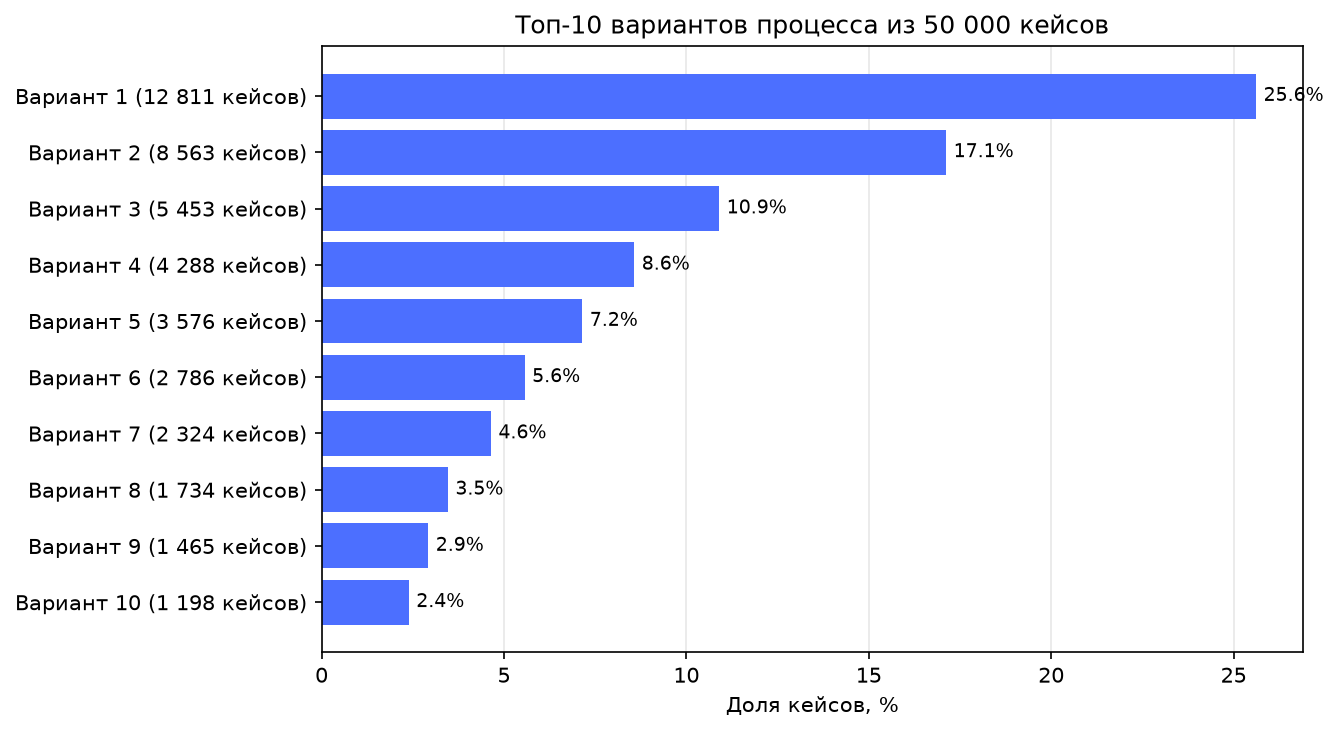

In [5]:
# ============================================================
# Ячейка 5: variant analysis — топ-10 вариантов → docs/img/variants.png
# ============================================================
t0 = time.perf_counter()
# get_variants_as_tuples возвращает dict: (активность, ...) -> число кейсов
pm4py_variants = pm4py.get_variants_as_tuples(LOG, **KEYS)
log.info(
    "Вариантов процесса: %d за %.1f с (%s кейсов)",
    len(pm4py_variants), time.perf_counter() - t0,
    f"{sum(pm4py_variants.values()):,}".replace(",", " "),
)

# Считаем то же самое по per_case: нужны ещё длительности и доли
variant_stats = pd.DataFrame(
    {"frequency": per_case["variant"].value_counts()}
)
variant_stats["share_percent"] = 100 * variant_stats["frequency"] / n_cases
variant_stats["avg_duration_days"] = per_case.groupby("variant")["duration_days"].mean()
variant_stats = variant_stats.sort_values("frequency", ascending=False)
variant_stats["variant_label"] = [" → ".join(variant) for variant in variant_stats.index]

assert int(variant_stats["frequency"].sum()) == n_cases, "Варианты не покрывают все кейсы"

top10 = variant_stats.head(10)
top_share_percent = float(top10["share_percent"].iloc[0])
log.info(
    "Топ-1 вариант покрывает %.2f%% кейсов (%s кейсов) — AC-5 требует ≥ 30%%",
    top_share_percent,
    f"{int(top10['frequency'].iloc[0]):,}".replace(",", " "),
)

display(
    top10[["variant_label", "frequency", "share_percent", "avg_duration_days"]]
    .reset_index(drop=True)
    .round(2)
)

# Bar chart: доля кейсов по вариантам (полные последовательности — в таблице выше)
fig, ax = plt.subplots(figsize=(9, 5))
positions = range(len(top10))
ax.barh(list(positions), top10["share_percent"], color="#4C6FFF")
ax.set_yticks(list(positions))
ax.set_yticklabels([f"Вариант {i + 1} ({freq:,.0f} кейсов)".replace(",", " ")
                    for i, freq in enumerate(top10["frequency"])])
ax.invert_yaxis()
ax.set_xlabel("Доля кейсов, %")
ax.set_title("Топ-10 вариантов процесса из 50 000 кейсов")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
for position, value in zip(positions, top10["share_percent"]):
    ax.text(value + 0.2, position, f"{value:.1f}%", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(IMG_VARIANTS, dpi=150, bbox_inches="tight")
plt.close(fig)
log.info("Сохранено: %s (%.0f КБ)", IMG_VARIANTS.relative_to(ROOT), IMG_VARIANTS.stat().st_size / 1024)

display(Image(filename=str(IMG_VARIANTS), width=750))

## 6. Bottlenecks

Для каждой активности считаем время до следующего события кейса (время ожидания, которое она «съедает»): среднее, σ, медиану, P90, долю кейсов с задержкой выше P90 и вклад в суммарную длительность. Топ-3 по вкладу — узкие места процесса (AC-6).

Две особенности данных, которые видно в таблице: у последнего события кейса (`Payment Made`) нет «следующего», поэтому в расчёт попадают 24 активности из 25; ожидание на `Customs Clearance` в генераторе ограничено 30 днями, из-за чего P90 совпадает с максимумом и доля «> P90» равна 0% — для этой активности метрика вырождена.

Bottleneck-таблица: 24 активностей за 1.2 с


  Legal Review Started           средняя 4.11 дн (σ 3.79), вклад 13.1%


  Legal Review Completed         средняя 4.09 дн (σ 3.74), вклад 12.9%


  Technical Review Completed     средняя 4.11 дн (σ 3.78), вклад 11.5%


,mean_days,std_days,median_days,p90_days,share_over_p90_percent,contribution_percent,n_events
concept:name,,,,,,,
Legal Review Started,4.11,3.79,3.00,8.42,9.90,13.06,56678
Legal Review Completed,4.09,3.74,2.96,8.33,9.91,12.94,56396
Technical Review Completed,4.11,3.78,3.00,8.42,9.94,11.52,50000
Technical Review Started,4.10,3.75,3.00,8.38,9.95,11.49,50000
Customs Clearance,10.62,9.50,6.96,30.00,0.00,11.29,18967
HSE Review Completed,1.63,2.10,1.00,3.58,9.94,4.42,48383
HSE Review Started,1.61,2.04,1.00,3.54,9.84,4.38,48623
Dispatch to Mine Site,1.63,2.11,1.00,3.58,9.90,4.34,47588
Inbound to Central Warehouse,1.62,2.08,0.96,3.58,9.94,4.32,47588


Сохранено: docs\img\bottlenecks.png (67 КБ)


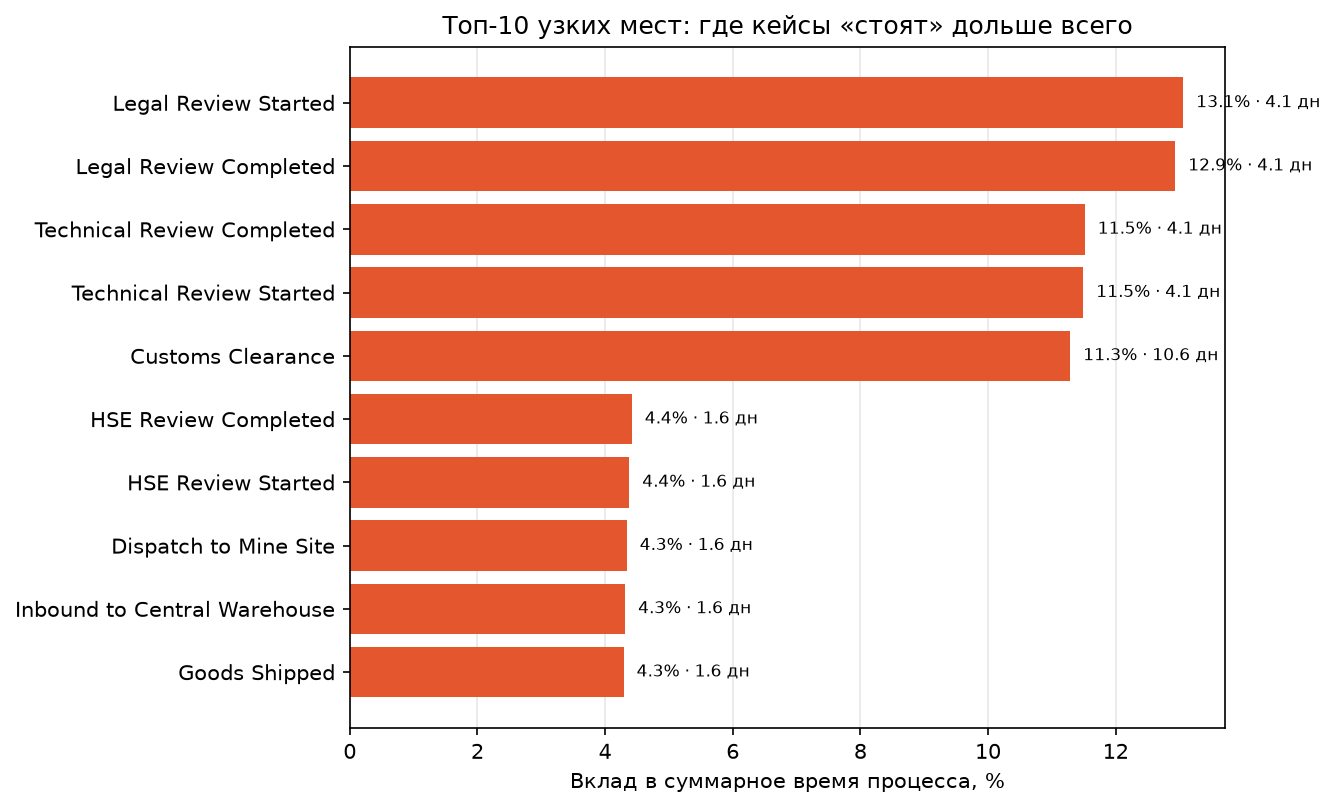

In [6]:
# ============================================================
# Ячейка 6: bottlenecks — где теряется время → docs/img/bottlenecks.png
# ============================================================
t0 = time.perf_counter()
# Время между соседними событиями кейса привязываем к ПРЕДШЕСТВУЮЩЕЙ активности:
# это ожидание, которое «съедает» данная активность (performance perspective).
waits = srt[["case:concept:name", "concept:name", "time:timestamp"]].copy()
waits["next_ts"] = waits.groupby("case:concept:name", sort=False)["time:timestamp"].shift(-1)
waits["wait_days"] = (waits["next_ts"] - waits["time:timestamp"]).dt.total_seconds() / 86400
# Последнее событие кейса не имеет «следующего» — из расчёта выпадает
waits = waits.dropna(subset=["wait_days"])

by_activity = waits.groupby("concept:name")["wait_days"]
bottlenecks = pd.DataFrame({
    "mean_days": by_activity.mean(),
    "std_days": by_activity.std(),
    "median_days": by_activity.median(),
    "p90_days": by_activity.quantile(0.9),
    "total_days": by_activity.sum(),
    "n_events": by_activity.count(),
})
bottlenecks["contribution_percent"] = 100 * bottlenecks["total_days"] / bottlenecks["total_days"].sum()
# AC-6: доля событий активности с задержкой выше её собственного P90
over_p90 = waits["wait_days"] > waits["concept:name"].map(bottlenecks["p90_days"])
bottlenecks["share_over_p90_percent"] = 100 * waits.assign(over_p90=over_p90).groupby("concept:name")["over_p90"].mean()
bottlenecks = bottlenecks.sort_values("contribution_percent", ascending=False)

log.info("Bottleneck-таблица: %d активностей за %.1f с", len(bottlenecks), time.perf_counter() - t0)
top3_bottlenecks = bottlenecks.head(3)
for activity, row in top3_bottlenecks.iterrows():
    log.info(
        "  %-30s средняя %.2f дн (σ %.2f), вклад %.1f%%",
        activity, row["mean_days"], row["std_days"], row["contribution_percent"],
    )

display(
    bottlenecks[[
        "mean_days", "std_days", "median_days", "p90_days",
        "share_over_p90_percent", "contribution_percent", "n_events",
    ]].head(10).round(2)
)

# Bar chart: топ-10 активностей по вкладу в общую длительность процесса
top_bn = bottlenecks.head(10)
fig, ax = plt.subplots(figsize=(9, 5.5))
positions = range(len(top_bn))
ax.barh(list(positions), top_bn["contribution_percent"], color="#E4572E")
ax.set_yticks(list(positions))
ax.set_yticklabels(top_bn.index)
ax.invert_yaxis()
ax.set_xlabel("Вклад в суммарное время процесса, %")
ax.set_title("Топ-10 узких мест: где кейсы «стоят» дольше всего")
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
for position, value, mean_days in zip(positions, top_bn["contribution_percent"], top_bn["mean_days"]):
    ax.text(value + 0.2, position, f"{value:.1f}% · {mean_days:.1f} дн", va="center", fontsize=8)
fig.tight_layout()
fig.savefig(IMG_BOTTLENECKS, dpi=150, bbox_inches="tight")
plt.close(fig)
log.info(
    "Сохранено: %s (%.0f КБ)",
    IMG_BOTTLENECKS.relative_to(ROOT), IMG_BOTTLENECKS.stat().st_size / 1024,
)

display(Image(filename=str(IMG_BOTTLENECKS), width=750))

## 7. Стоимость простоя

`Σ (duration_days × downtime_cost_per_day)` по всем кейсам (AC-4). Длительность считается из событий: в `cases.csv` колонки `duration_days` нет.

In [7]:
# ============================================================
# Ячейка 7: стоимость простоя (AC-4)
# ============================================================
# В cases.csv нет duration_days, поэтому длительность берём из событий:
# duration_days = (max(timestamp) - min(timestamp)) по кейсу.
per_case["delay_cost"] = per_case["duration_days"] * per_case["downtime_cost_per_day"]

total_cost = per_case["delay_cost"].sum()
total_days = per_case["duration_days"].sum()


def rub(value: float) -> str:
    """Форматирует рубли с пробелами между разрядами: 1 234 567 ₽."""
    return f"{value:,.0f}".replace(",", " ") + " ₽"


log.info("Кейсов в расчёте:              %s", f"{len(per_case):,}".replace(",", " "))
log.info("Суммарная длительность:        %s дней", f"{total_days:,.0f}".replace(",", " "))
log.info("Стоимость простоя (всего):     %s", rub(total_cost))
log.info("Стоимость простоя (млрд ₽):    %.1f", total_cost / 1e9)
log.info("Средняя стоимость одного кейса: %s", rub(total_cost / len(per_case)))

# Разбивка по категориям — для сверки с site/data/overview.json
cost_by_category = per_case.groupby("category").agg(
    cases=("delay_cost", "size"),
    total_cost=("delay_cost", "sum"),
    avg_duration_days=("duration_days", "mean"),
)
cost_by_category["share_percent"] = 100 * cost_by_category["total_cost"] / total_cost
cost_by_category = cost_by_category.sort_values("total_cost", ascending=False)

# Отменённые кейсы (is_rejected = 1) по спеке не входят в «среднюю длительность»,
# но в общую стоимость простоя входят — показываем их отдельно.
rejected_mask = per_case["is_rejected"] == 1
log.info(
    "Из них отменённые кейсы: %s (%s, %.1f%% общей суммы)",
    f"{int(rejected_mask.sum()):,}".replace(",", " "),
    rub(per_case.loc[rejected_mask, "delay_cost"].sum()),
    100 * per_case.loc[rejected_mask, "delay_cost"].sum() / total_cost,
)

display(cost_by_category.round(2))

Кейсов в расчёте:              50 000


Суммарная длительность:        1 783 770 дней


Стоимость простоя (всего):     534 392 476 278 ₽


Стоимость простоя (млрд ₽):    534.4


Средняя стоимость одного кейса: 10 687 850 ₽


Из них отменённые кейсы: 2 412 (14 299 498 306 ₽, 2.7% общей суммы)


,cases,total_cost,avg_duration_days,share_percent
category,,,,
ЗИП (запчасти),10056,1.082129e+11,35.83,20.25
Подрядные работы,10050,1.075062e+11,35.57,20.12
Обслуживание оборудования,9972,1.072926e+11,35.87,20.08
Химические реагенты,9945,1.056918e+11,35.53,19.78
Спецтехника,9977,1.056890e+11,35.58,19.78


## 8. Самопроверка: сводка по Acceptance Criteria

In [8]:
# ============================================================
# Ячейка 8: самопроверка — сводка по Acceptance Criteria
# ============================================================
png_artifacts = [IMG_DFG, IMG_PETRI, IMG_VARIANTS, IMG_BOTTLENECKS]
existing_png = [path for path in png_artifacts if path.exists() and path.stat().st_size > 20_000]

summary_rows = [
    {
        "AC": "AC-2",
        "Требование": "DFG: ≥ 20 узлов и ≥ 25 рёбер",
        "Факт": f"{len(dfg_nodes)} узлов, {len(dfg)} рёбер",
        "Статус": "PASS" if len(dfg_nodes) >= 20 and len(dfg) >= 25 else "FAIL",
    },
    {
        "AC": "AC-5",
        "Требование": "топ-1 вариант покрывает ≥ 30% кейсов",
        "Факт": f"{top_share_percent:.2f}% ({len(variant_stats)} вариантов всего)",
        "Статус": "PASS" if top_share_percent >= 30 else "FAIL",
    },
    {
        "AC": "AC-6",
        "Требование": "средняя длительность, σ, P90, топ-3 по вкладу",
        "Факт": "топ-3: " + ", ".join(top3_bottlenecks.index),
        "Статус": "PASS" if len(top3_bottlenecks) == 3 else "FAIL",
    },
    {
        "AC": "AC-4",
        "Требование": "стоимость простоя = Σ duration_days × downtime_cost_per_day",
        "Факт": rub(total_cost),
        "Статус": "PASS" if total_cost > 0 else "FAIL",
    },
    {
        "AC": "AC-9",
        "Требование": "PNG в docs/img/ (DFG, Petri net, bottlenecks)",
        "Факт": f"{len(existing_png)} из {len(png_artifacts)} файлов",
        "Статус": "PASS" if len(existing_png) == len(png_artifacts) else "FAIL",
    },
    {
        "AC": "AC-1",
        "Требование": "XES-совместимость (NULL, монотонность, дубли)",
        "Факт": "0 нарушений" if xes_ok else str(xes_checks),
        "Статус": "PASS" if xes_ok else "FAIL",
    },
]

summary = pd.DataFrame(summary_rows)
display(summary)

passed = int((summary["Статус"] == "PASS").sum())
log.info("Итог самопроверки: %d из %d PASS", passed, len(summary))
log.info("Артефакты: %s", ", ".join(str(path.relative_to(ROOT)) for path in existing_png))

,AC,Требование,Факт,Статус
0,AC-2,DFG: ≥ 20 узлов и ≥ 25 рёбер,"25 узлов, 28 рёбер",PASS
1,AC-5,топ-1 вариант покрывает ≥ 30% кейсов,25.62% (80 вариантов всего),FAIL
2,AC-6,"средняя длительность, σ, P90, топ-3 по вкладу","топ-3: Legal Review Started, Legal Review Comp...",PASS
3,AC-4,стоимость простоя = Σ duration_days × downtime...,534 392 476 278 ₽,PASS
4,AC-9,"PNG в docs/img/ (DFG, Petri net, bottlenecks)",4 из 4 файлов,PASS
5,AC-1,"XES-совместимость (NULL, монотонность, дубли)",0 нарушений,PASS


Итог самопроверки: 5 из 6 PASS


Артефакты: docs\img\dfg.png, docs\img\petri_net.png, docs\img\variants.png, docs\img\bottlenecks.png
